Este notebook tem como objetivo acumular toda a exploração realizada para criação das respostas, slides e apresentação, com os resultados estatísticos que corroboram com o que foi apresentado.

Setup

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np

from scipy.stats import fisher_exact, chi2_contingency, kruskal

In [3]:
df = pd.read_csv('../data/raw/desafio_nps_fase_1.csv')

In [9]:
print('Há valores nulos:', df.isna().any().any())

Há valores nulos: False


In [6]:
print('Customer ID é único:', df['customer_id'].nunique() == len(df))

print('Order ID é único:', df['order_id'].nunique() == len(df))

Customer ID é único: True
Order ID é único: True


In [10]:
df.describe()

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
count,2500.00000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,43.396000,61.322400,51250.50000,434.259740,3.470800,29.745620,6.004000,8.022000,2.187200,38.217016,2.005600,1.519600,5.485600,4.378600,0.087200,4.150400,2.941600
std,721.83216,14.888487,34.478729,721.83216,289.772497,1.687331,29.225603,3.159743,3.770411,1.454442,12.076074,0.815497,1.231512,3.458002,2.510229,0.282184,1.784223,2.378957
min,1.00000,18.000000,1.000000,50001.00000,7.760000,1.000000,0.020000,1.000000,2.000000,0.000000,2.620000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,625.75000,31.000000,31.000000,50625.75000,220.245000,2.000000,8.885000,3.000000,5.000000,1.000000,29.927500,1.000000,1.000000,2.000000,2.600000,0.000000,3.000000,0.700000
50%,1250.50000,43.000000,62.000000,51250.50000,375.515000,3.000000,20.935000,6.000000,8.000000,2.000000,38.500000,2.000000,1.000000,6.000000,4.400000,0.000000,4.000000,2.800000
75%,1875.25000,56.000000,91.000000,51875.25000,577.290000,5.000000,40.832500,9.000000,11.000000,3.000000,46.270000,3.000000,2.000000,8.000000,6.100000,0.000000,5.000000,4.800000
max,2500.00000,69.000000,119.000000,52500.00000,1983.810000,6.000000,230.330000,11.000000,14.000000,8.000000,76.130000,3.000000,7.000000,11.000000,10.000000,1.000000,11.000000,10.000000


Olhando o describe, o que mais me chamou atenção foi que a média e 50% de complaints_count é 4, que parece ser um número muito alto para complaints_count

In [11]:
df['complaints_count'].value_counts()

complaints_count
4     600
3     507
5     444
2     277
6     266
7     169
1     122
8      63
0      23
9      16
10     11
11      2
Name: count, dtype: int64

Faço agora algumas verificações, validando se o nps_score tem o shape esperado (0 e 10 muito altos, outros menores) e também se tem alguma região mais representada nos dados.

<Axes: >

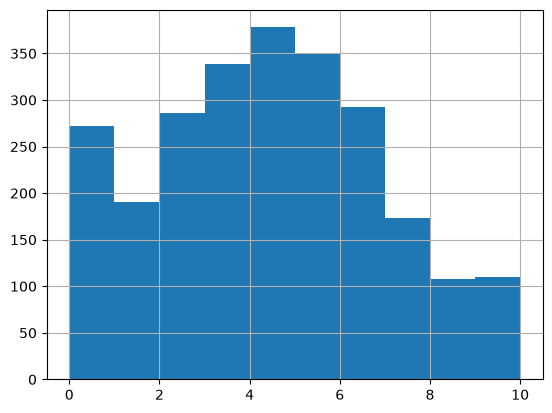

In [ ]:
df['nps_score'].hist()

<Axes: >

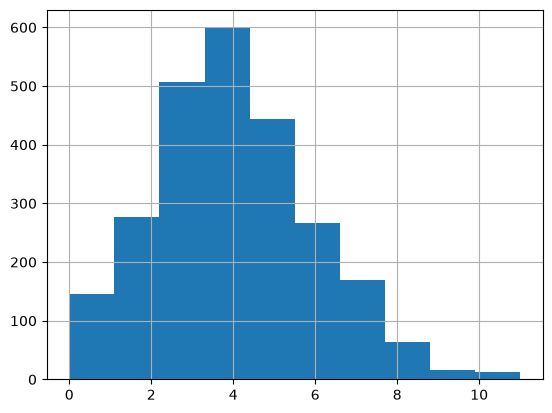

In [ ]:
df['complaints_count'].hist()

In [ ]:
df['customer_region'].value_counts()

customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

A partir disso, começo a procurar correlações na base, removendo customer_region por ser categórica.

In [14]:
df_corr = df[df.select_dtypes(include=['float64', 'int64']).columns]
df_corr.corr()['nps_score'].sort_values(ascending=False)

nps_score                    1.000000
repeat_purchase_30d          0.570324
csat_internal_score          0.563952
order_value                  0.036990
delivery_attempts            0.027680
discount_value               0.025104
payment_installments         0.023718
customer_id                  0.015162
order_id                     0.015162
items_quantity               0.011468
delivery_time_days           0.000925
customer_tenure_months      -0.009711
customer_age                -0.009936
freight_value               -0.041087
resolution_time_days        -0.191392
customer_service_contacts   -0.350845
complaints_count            -0.496800
delivery_delay_days         -0.597260
Name: nps_score, dtype: float64

Aqui foquei nas correlações com nps_score por ser a variável de interesse. As variáveis que chamam atenção são:
```
repeat_purchase_30d          0.570324
csat_internal_score          0.563952
resolution_time_days        -0.191392
customer_service_contacts   -0.350845
complaints_count            -0.496800
delivery_delay_days         -0.597260
```

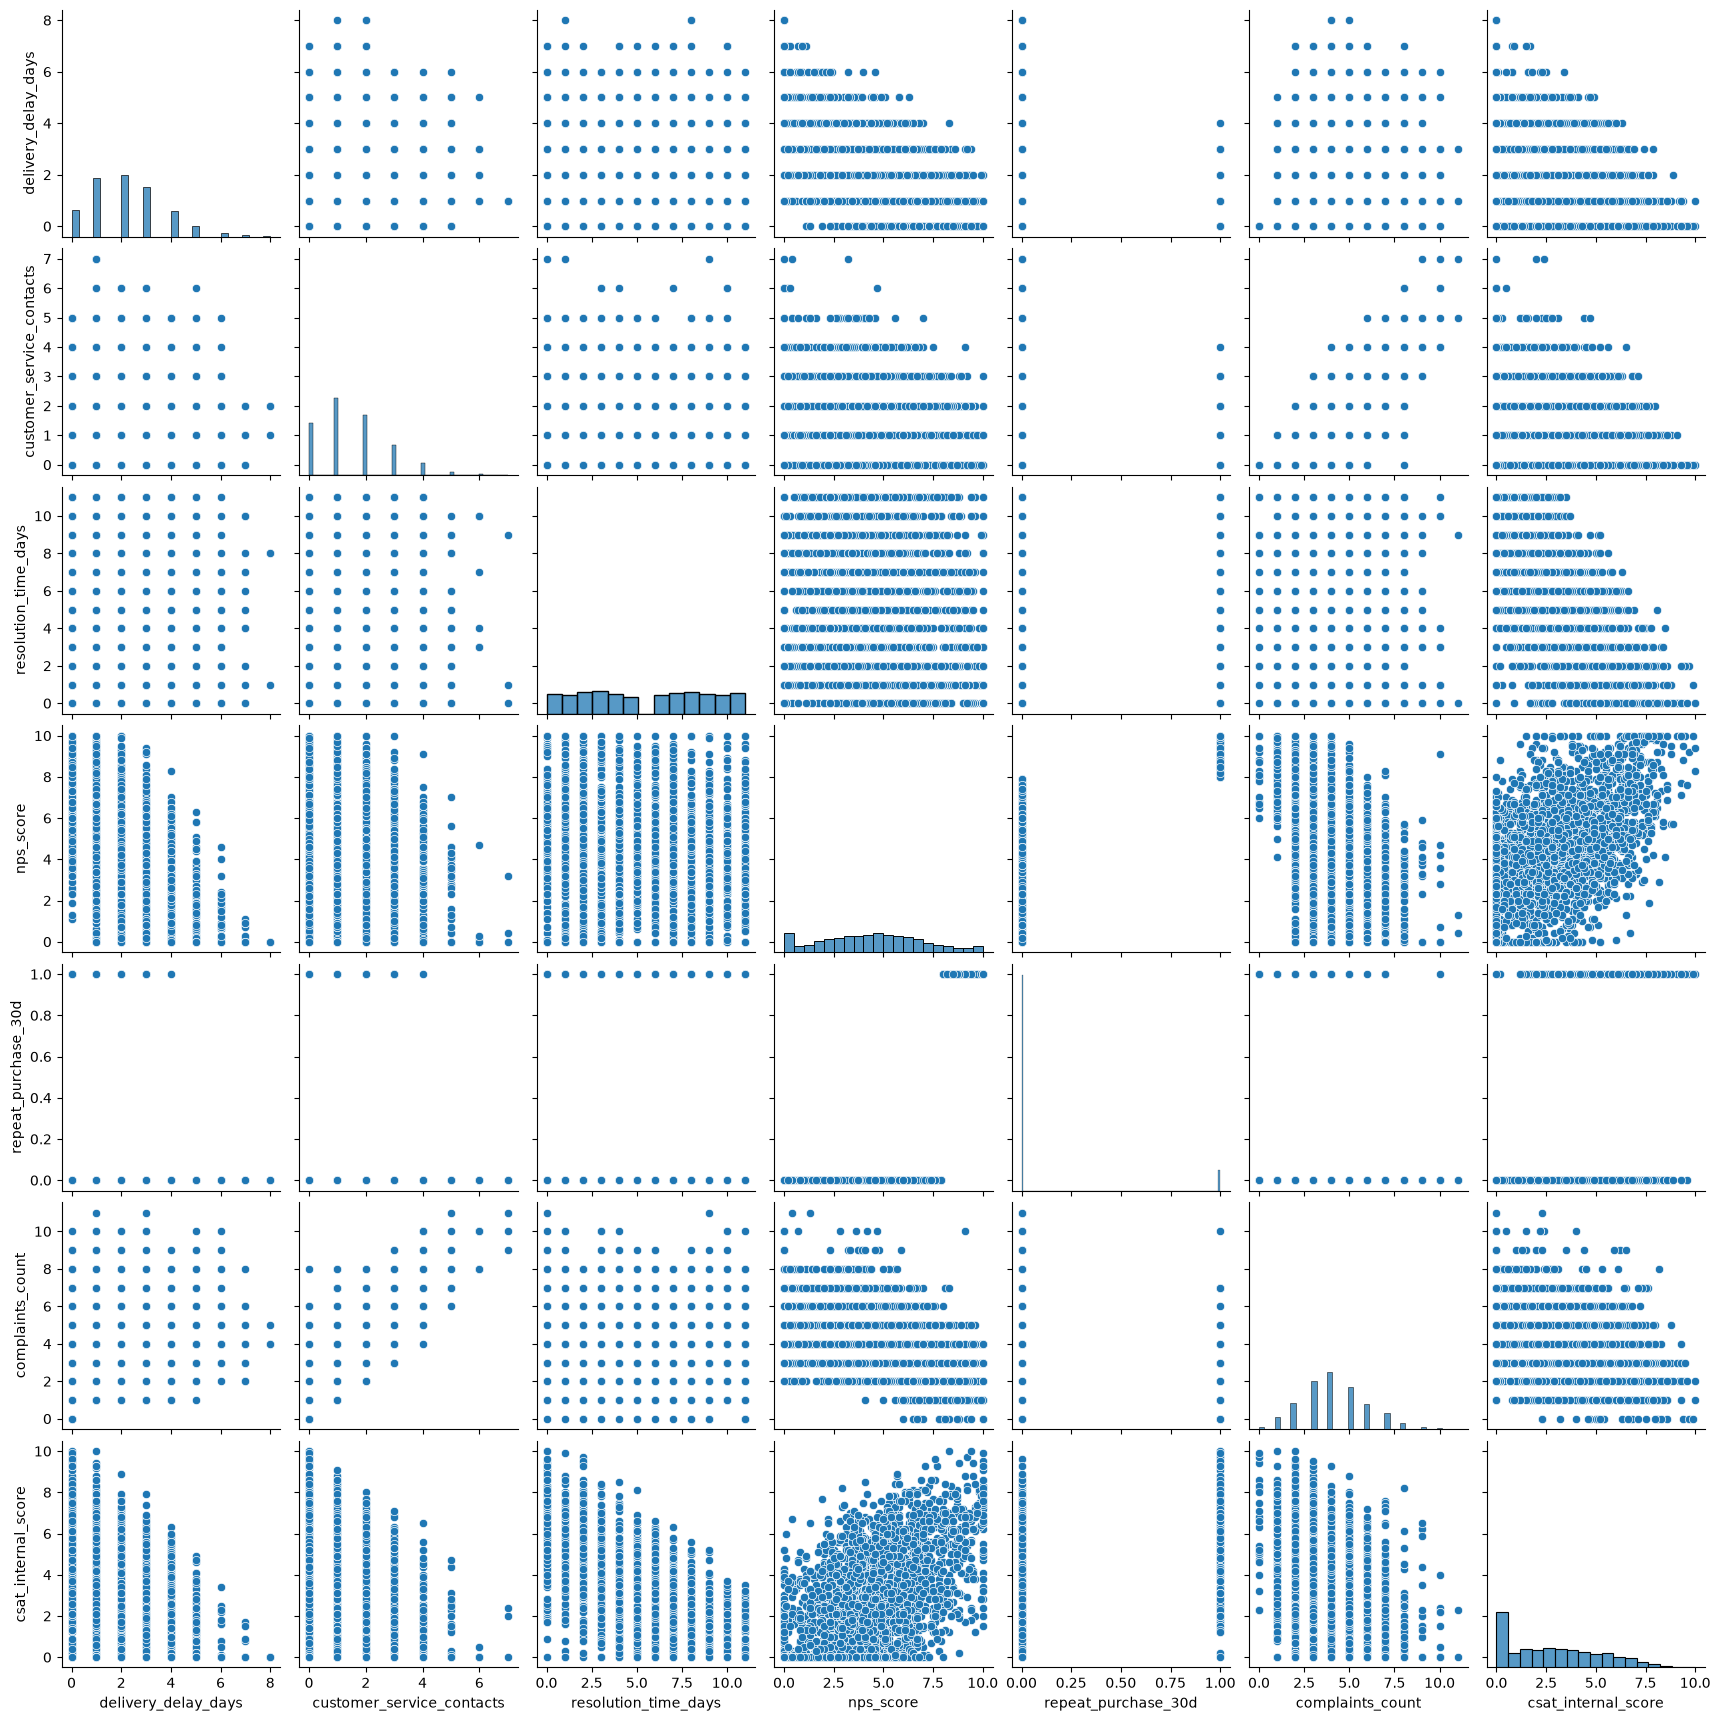

In [16]:
sns.pairplot(df_corr[['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'nps_score', 'repeat_purchase_30d', 'complaints_count', 'csat_internal_score']])

Também percebo que pode existir relação entre csat_internal_score, resolution_time_days, customer_service_contacts e complaints_count, por todos serem relacionados ao suporte.

Com base no pairplot, faço outras verificações como repeat_purchase_30d x nps_score, por ter um limite de score visível que muda o repeat_purchase_30d.

Também verifico o customer_region separadamente por ser a única coluna categórica. Não percebo nada nessa coluna que mereça uma avaliação mais aprofundada nesse momento.

In [18]:
df[['repeat_purchase_30d', 'nps_score']].groupby('repeat_purchase_30d').agg({'nps_score': ['mean', 'std', 'count', 'min', 'max']}).reset_index()

repeat_purchase_30d nps_score                           
                           mean       std count  min   max
0                   0  3.936196  2.147671  2282  0.0   7.9
1                   1  9.009633  0.691521   218  8.0  10.0

In [19]:
df[['customer_region', 'nps_score']].groupby('customer_region').agg({'nps_score': ['mean', 'std', 'count', 'min', 'max']}).reset_index()

customer_region nps_score                           
                       mean       std count  min   max
0    Centro-Oeste  4.209829  2.625968   468  0.0  10.0
1        Nordeste  4.421649  2.434829   485  0.0  10.0
2           Norte  4.382609  2.485931   506  0.0  10.0
3         Sudeste  4.373846  2.491552   520  0.0  10.0
4             Sul  4.490979  2.516739   521  0.0  10.0

Continuo a exploração das variáveis anteriores, agora arredondando o nps para baixo, verificando se há alteração nos gráficos

In [20]:
df_corr['nps_score_int'] = np.floor(df_corr['nps_score'])

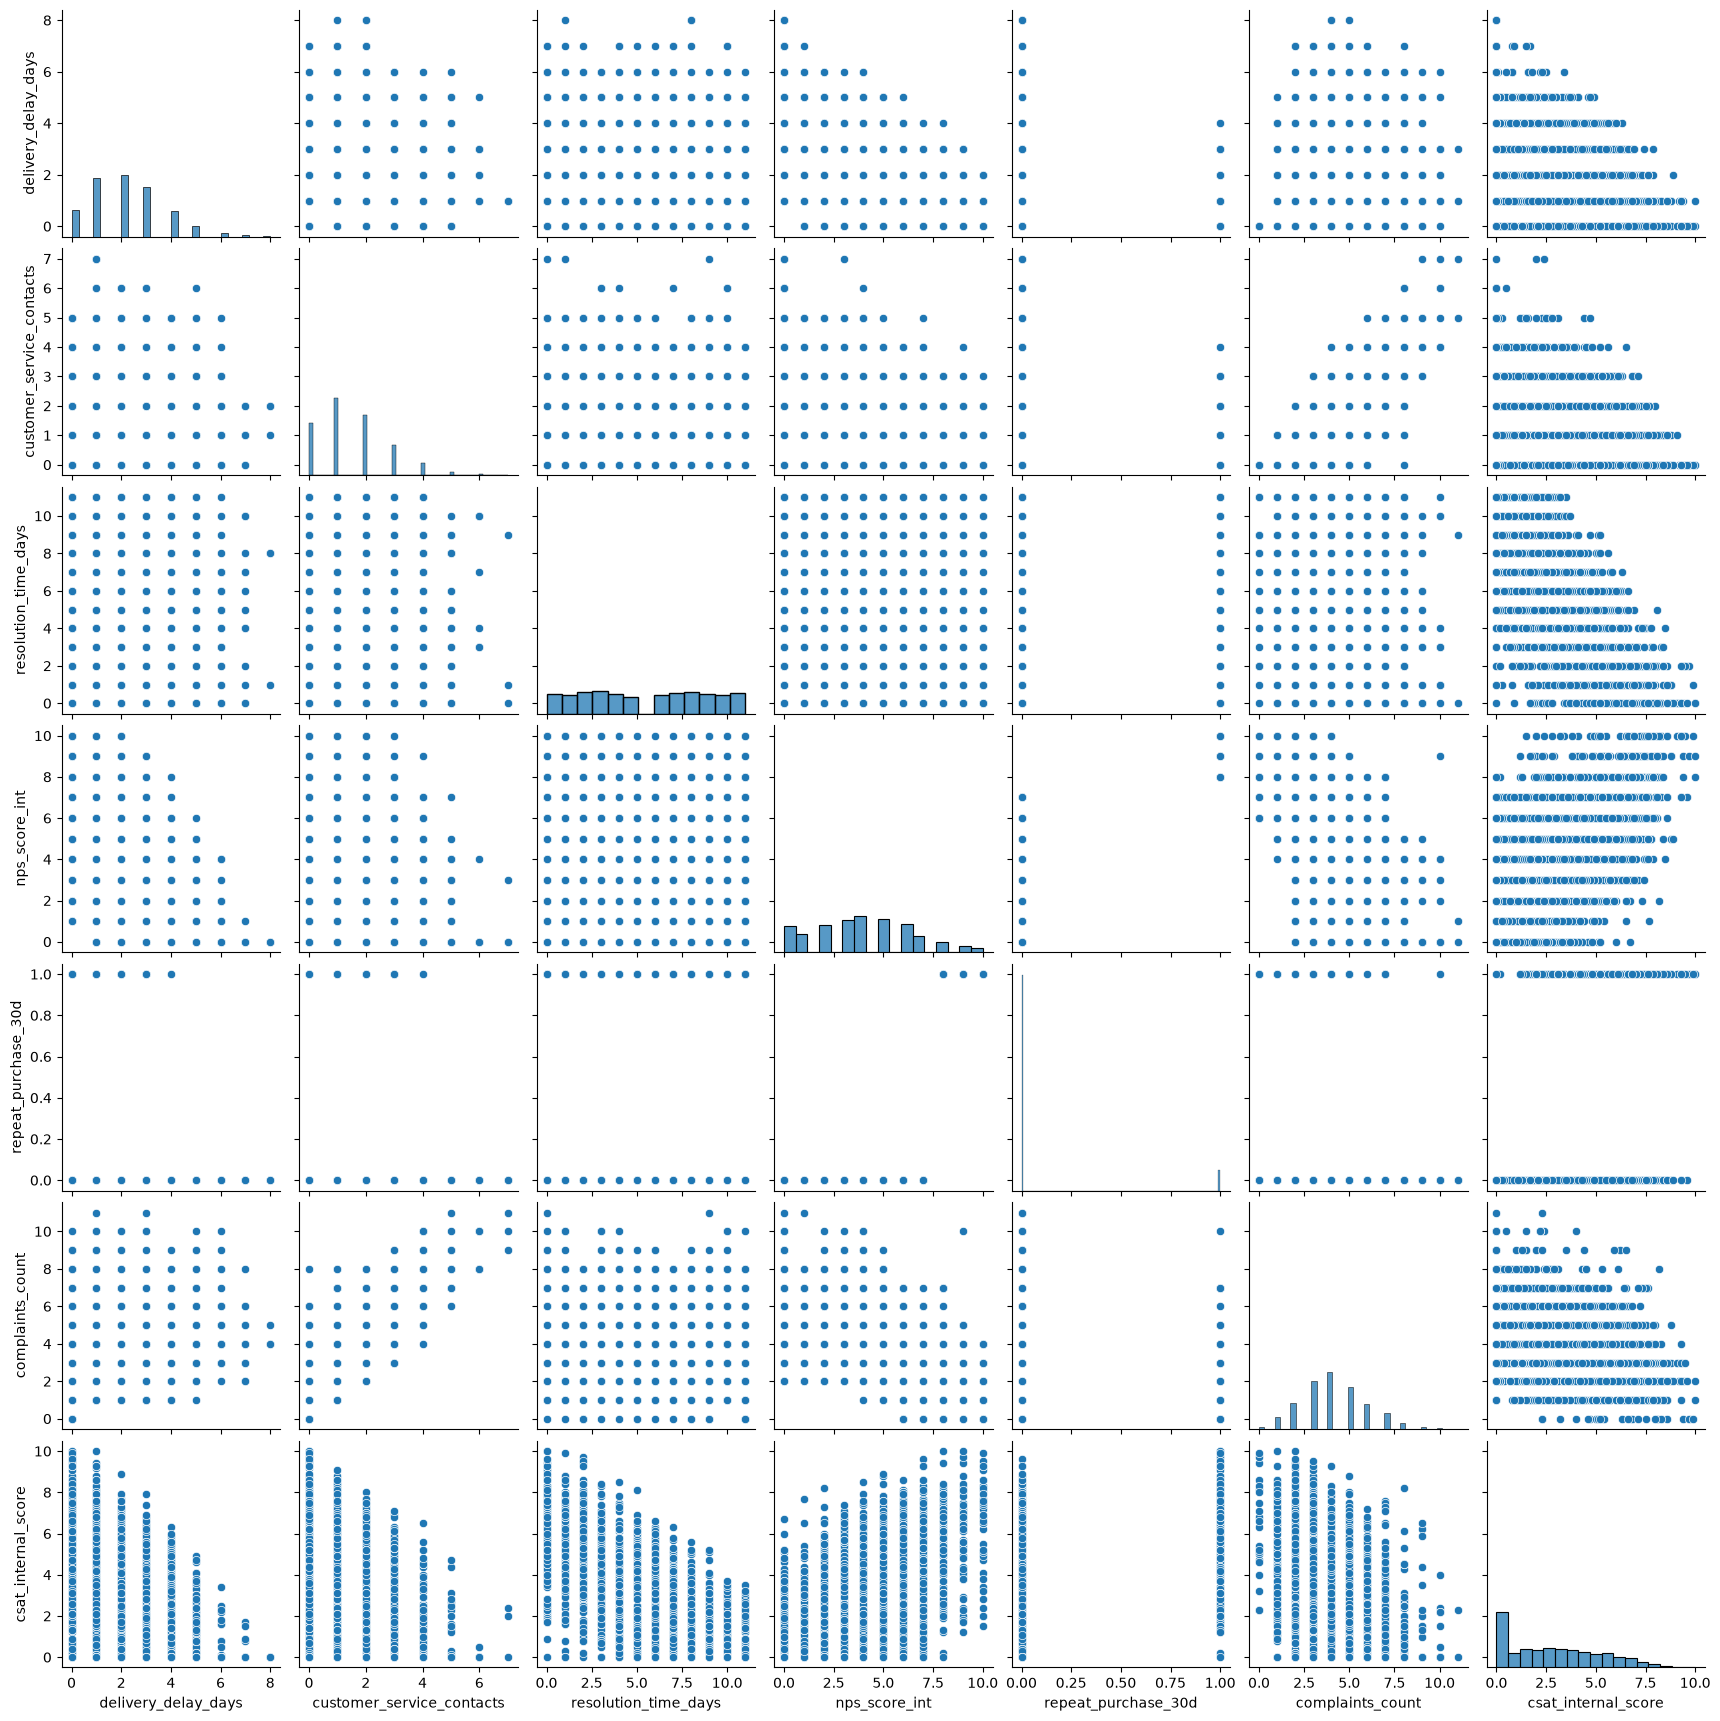

In [22]:
sns.pairplot(df_corr[['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'nps_score_int', 'repeat_purchase_30d', 'complaints_count', 'csat_internal_score']])

<Axes: xlabel='complaints_count'>

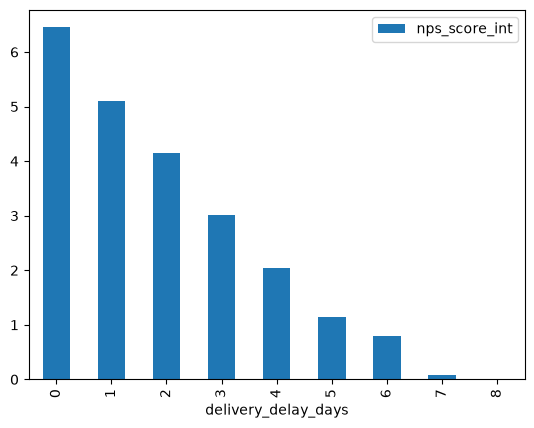

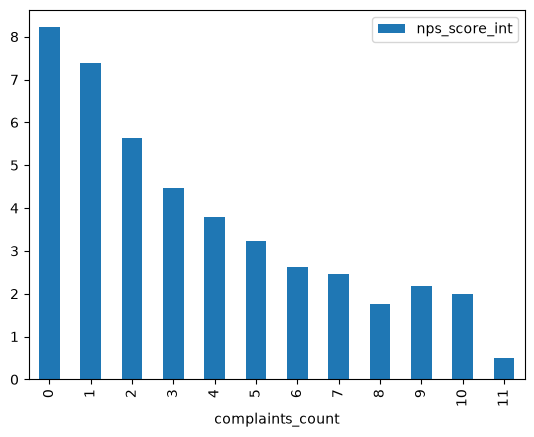

In [23]:
df_corr[['delivery_delay_days', 'nps_score_int']].groupby('delivery_delay_days').mean().plot(kind='bar')
df_corr[['complaints_count', 'nps_score_int']].groupby('complaints_count').mean().plot(kind='bar')

Nesse caso, não encontrei nenhuma nova informação que julguei relevante.

Também criei uma variável categórica de promotor, detrator e neutro para o nps_score, e verifiquei algumas informações sobre as variáveis sendo investigadas.

In [24]:
df['nps_cat'] = df['nps_score'].apply(lambda x: 'detrator' if x <= 6 else ('neutro' if x < 9 else 'promotor'))

In [26]:
df[['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'nps_cat',]].groupby('nps_cat').agg({'delivery_delay_days': ['mean', 'std', 'count', 'min', 'max'], 'customer_service_contacts': ['mean', 'std', 'count', 'min', 'max'], 'resolution_time_days': ['mean', 'std', 'count', 'min', 'max'], 'complaints_count': ['mean', 'std', 'count', 'min', 'max']}).T

nps_cat                             detrator      neutro    promotor
delivery_delay_days       mean      2.534306    1.294991    0.718182
                          std       1.430663    1.005650    0.779694
                          count  1851.000000  539.000000  110.000000
                          min       0.000000    0.000000    0.000000
                          max       8.000000    5.000000    3.000000
customer_service_contacts mean      1.694219    1.092764    0.672727
                          std       1.265537    0.980632    0.836211
                          count  1851.000000  539.000000  110.000000
                          min       0.000000    0.000000    0.000000
                          max       7.000000    5.000000    4.000000
resolution_time_days      mean      5.793625    4.792208    3.700000
                          std       3.419117    3.433578    3.215644
                          count  1851.000000  539.000000  110.000000
                          min       0.000000    0.000000    0.000000
                          max      11.000000   11.000000   11.000000
complaints_count          mean      4.622907    2.910946    2.272727
                          std       1.625271    1.495797    1.470874
                          count  1851.000000  539.000000  110.000000
                          min       0.000000    0.000000    0.000000
                          max      11.000000    7.000000   10.000000

Como as variáveis de suporte podem ter relações mais complexas entre si, comecei pela variável mais isolada (assunto diferente) e aparentemente mais relevante (coef -0.59), delivery_delay_days.


Aqui eu verifico o nps médio por dias de atraso, e também faço a evolução do percentual de detratores por dia de atraso.

                     detrator
delivery_delay_days          
0                    0.364621
1                    0.596748
2                    0.753870
3                    0.897143
4                    0.959259
5                    0.991379
6                    1.000000
7                    1.000000
8                    1.000000


<Axes: xlabel='delivery_delay_days'>

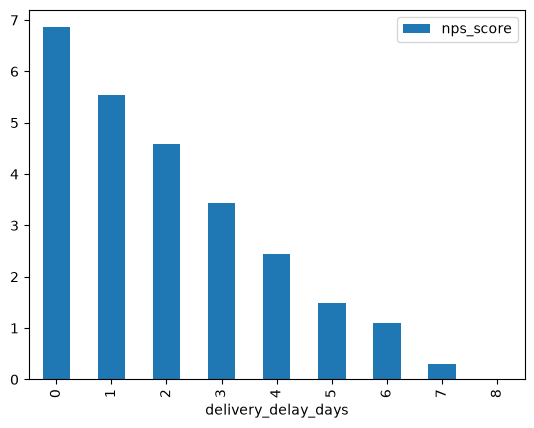

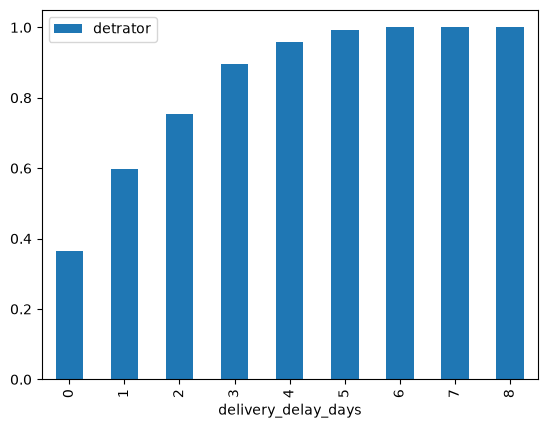

In [27]:
df[['delivery_delay_days', 'nps_score']].groupby('delivery_delay_days').mean().plot(kind='bar')
df['detrator'] = df['nps_cat'] == 'detrator'
print(df[['delivery_delay_days', 'detrator']].groupby('delivery_delay_days').mean())
df[['delivery_delay_days', 'detrator']].groupby('delivery_delay_days').mean().plot(kind='bar')

Nesse último gráfico, o que chama atenção é principalmente que delivery_delay_days == 0 ainda assim tem um valor alto de detratores (36%), o que pode indicar que a entrega no prazo não garante score nps alto. Para entender esse grupo de clientes, filtro por delivery_delay_days == 0 e valido novamente as informações anteriores. Aqui, estou investigando como os clientes se comportam quando não há problema de entrega.

In [29]:
df_no_delays = df_corr[df_corr['delivery_delay_days'] == 0]

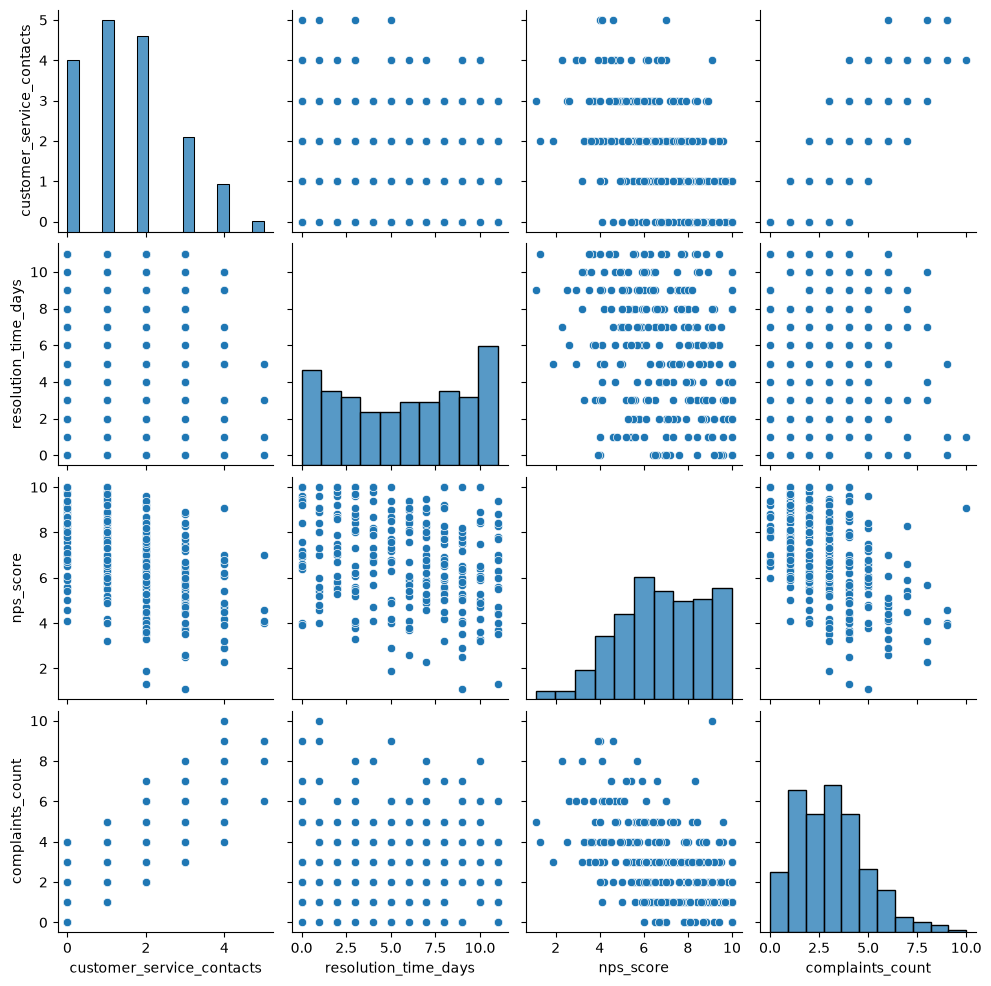

In [30]:
sns.pairplot(df_no_delays[['customer_service_contacts', 'resolution_time_days', 'nps_score', 'complaints_count']])

In [32]:
df_no_delays.corr()['nps_score'].sort_values(ascending=False)

nps_score                    1.000000
nps_score_int                0.988829
repeat_purchase_30d          0.790023
csat_internal_score          0.487219
discount_value               0.072552
delivery_time_days           0.063238
order_value                  0.054675
customer_age                 0.050211
payment_installments         0.035706
delivery_attempts            0.019679
freight_value                0.014417
items_quantity              -0.009292
customer_tenure_months      -0.041092
customer_id                 -0.065746
order_id                    -0.065746
resolution_time_days        -0.291225
complaints_count            -0.500607
customer_service_contacts   -0.503971
delivery_delay_days               NaN
Name: nps_score, dtype: float64

Aqui, nenhuma outra variável ficou em evidência, apenas as variáveis já identificadas. 

Investigo se a customer_region poderia explicar essa diferença de entrega, isso porque regiões mais distantes de SP poderiam estar puxando o score para baixo.

In [34]:
print(df[(df['delivery_delay_days'] == 0) & (df['detrator'] == 1)].groupby('customer_region')['detrator'].count() / df[(df['delivery_delay_days'] == 0) & (df['detrator'] == 1)]['detrator'].count())
df[(df['detrator'] == 1)].groupby('customer_region')['detrator'].count() / df[(df['detrator'] == 1)]['detrator'].count()

customer_region
Centro-Oeste    0.178218
Nordeste        0.168317
Norte           0.267327
Sudeste         0.158416
Sul             0.227723
Name: detrator, dtype: float64


customer_region
Centro-Oeste    0.188006
Nordeste        0.193949
Norte           0.203674
Sudeste         0.209616
Sul             0.204754
Name: detrator, dtype: float64

Aqui achei um pouco alto o percentual do Norte em relação aos outros. Para saber se ele é relevante, escolhi validar Norte vs Outros com e sem delivery_delay_days.

Nesse caso

In [35]:
df_sem_atraso = df[df['delivery_delay_days'] == 0].copy()
df_sem_atraso['is_norte'] = df_sem_atraso['customer_region'] == 'Norte'

In [36]:
pd.crosstab(df_sem_atraso['is_norte'], df_sem_atraso['detrator'])

detrator,False,True
is_norte,,
False,142,74
True,34,27


In [37]:
fisher_exact(pd.crosstab(df_sem_atraso['is_norte'], df_sem_atraso['detrator']))

SignificanceResult(statistic=np.float64(1.5238473767885532), pvalue=np.float64(0.17568395274163937))

In [38]:
from scipy.stats import chi2_contingency

chi2_contingency(pd.crosstab(df_sem_atraso['is_norte'], df_sem_atraso['detrator']))

Chi2ContingencyResult(statistic=np.float64(1.6453490006189826), pvalue=np.float64(0.19959314095333713), dof=1, expected_freq=array([[137.24187726,  78.75812274],
       [ 38.75812274,  22.24187726]]))

Como ambos os p-valores dos testes Fisher(p=0.175) e Qui-Quadrado(p=0.199) são maiores que 0.05, assumo que não há evidências suficientes para afirmar que a região Norte tem uma proporção de detratores maior quando não há atraso.

Obs: a partir daqui criei um novo notebook chamado "investigacoes_suporte.ipynb"

O objetivo é validar então uma hipótese: Quando não há atraso, o suporte é o maior problema para notas NPS baixas.

In [60]:
df_sem_atraso = df[df['delivery_delay_days'] == 0]
df_sem_atraso_sem_contatos_suporte = df[(df['delivery_delay_days'] == 0) & (df['customer_service_contacts'] == 0)]

<Axes: >

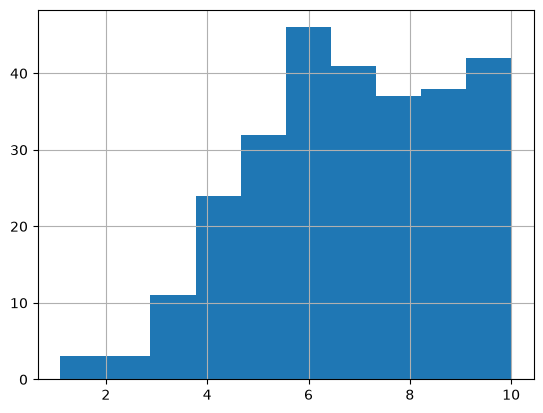

In [61]:
df_sem_atraso['nps_score'].hist()

<Axes: >

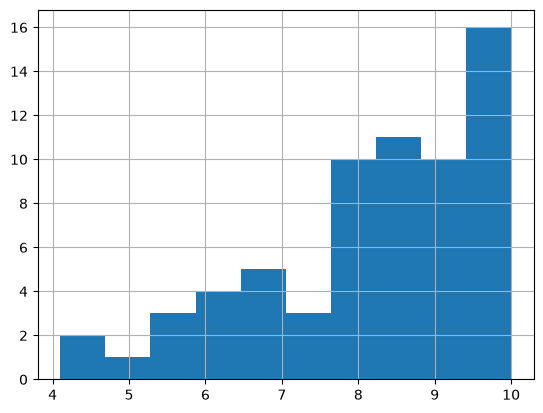

In [62]:
df_sem_atraso_sem_contatos_suporte['nps_score'].hist()

In [63]:
df_sem_atraso['nps_cat'].value_counts(normalize=True)

nps_cat
neutro      0.454874
detrator    0.364621
promotor    0.180505
Name: proportion, dtype: float64

In [ ]:
df_sem_atraso_sem_contatos_suporte['nps_cat'].value_counts(normalize=True)

nps_cat
neutro      0.565217
promotor    0.391304
detrator    0.043478
Name: proportion, dtype: float64

Porém quando comecei a investigar, notei que o gráfico "sem atrasos e sem contato com suporte" ficou estranho, com valores no eixo y muito baixos. Como customer_service_contacts e complaints_count representam "ter problema", criei uma nova variável para validar a união de ambos.

In [64]:
df['had_cs_problem'] = (df['customer_service_contacts'] > 0) | (df['complaints_count'] > 0)
print(df[df['had_cs_problem'] == 1]['nps_cat'].value_counts(normalize=True))
print(df['had_cs_problem'].value_counts(normalize=True))
df['had_cs_problem'].value_counts(normalize=False)

nps_cat
detrator    0.746871
neutro      0.212354
promotor    0.040775
Name: proportion, dtype: float64
had_cs_problem
True     0.9908
False    0.0092
Name: proportion, dtype: float64


had_cs_problem
True     2477
False      23
Name: count, dtype: int64

Aqui então o que chamou atenção é que 99% das respostas teve algum tipo de problema, seja ter que contatar o suporte, ou fazer uma reclamação. Com isso eu isolei esses 99% para trabalhar apenas com eles.

In [41]:
df_cs_problem = df[df['had_cs_problem'] == 1]
df_cs_problem[['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'nps_cat',]].groupby('nps_cat').agg({'delivery_delay_days': ['mean', 'std', 'median'], 'customer_service_contacts': ['mean', 'std', 'median'], 'resolution_time_days': ['mean', 'std', 'median'], 'complaints_count': ['mean', 'std', 'median']}).T

nps_cat                           detrator    neutro  promotor
delivery_delay_days       mean    2.535676  1.326996  0.782178
                          std     1.429835  0.996906  0.782355
                          median  2.000000  1.000000  1.000000
customer_service_contacts mean    1.695135  1.119772  0.732673
                          std     1.265265  0.977318  0.847244
                          median  2.000000  1.000000  1.000000
resolution_time_days      mean    5.792432  4.760456  3.633663
                          std     3.419656  3.432566  3.155068
                          median  6.000000  4.000000  3.000000
complaints_count          mean    4.625405  2.982890  2.475248
                          std     1.622150  1.441458  1.360838
                          median  4.000000  3.000000  2.000000

Vejo aqui que, para delivery_delay_days, o máximo de delay aceitável pelo cliente é 1 dia. Após isso ele vira detrator.

Para neutro:

Típico:

1 dia de atraso

1 contato com CS

4 dias de resolução

3 reclamações

Para detrator:

Típico:

2 dias de atraso

2 contatos com CS

6 dias de resolução de ticket

4 reclamações

A partir disso, busco responder se essa progressão é real ou poderia ser aleatória

In [42]:
from scipy.stats import kruskal

promotor = df_cs_problem[df_cs_problem['nps_cat'] == 'promotor'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]
neutro = df_cs_problem[df_cs_problem['nps_cat'] == 'neutro'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]
detrator = df_cs_problem[df_cs_problem['nps_cat'] == 'detrator'][['delivery_delay_days', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']]

In [43]:
kruskal(promotor, neutro, detrator)

KruskalResult(statistic=array([424.33328356, 138.02958758,  66.86769704, 484.91330728]), pvalue=array([7.19777442e-093, 1.06477020e-030, 3.01900672e-015, 5.03979908e-106]))

O teste indica que a progressão é real. A partir disso faço o mesmo gráfico para as outras variáveis de suporte que fiz para o atraso de entrega

                  detrator
complaints_count          
0                 0.043478
1                 0.081967
2                 0.433213
3                 0.676529
4                 0.811667
5                 0.882883
6                 0.936090
7                 0.934911
8                 1.000000
9                 1.000000
10                0.909091
11                1.000000


<Axes: xlabel='complaints_count'>

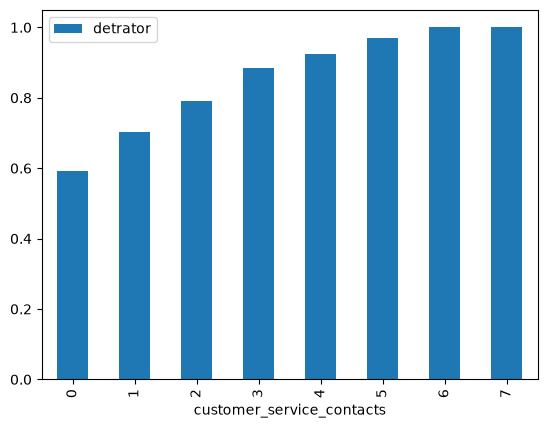

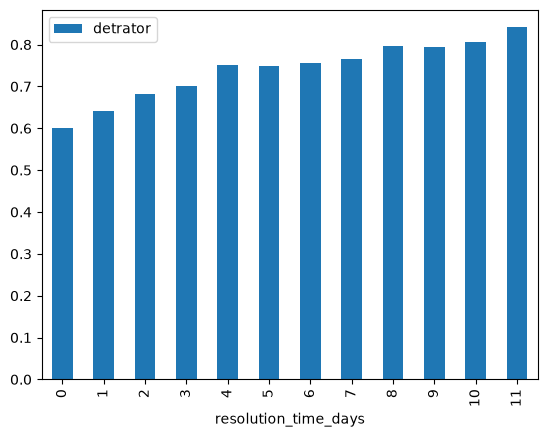

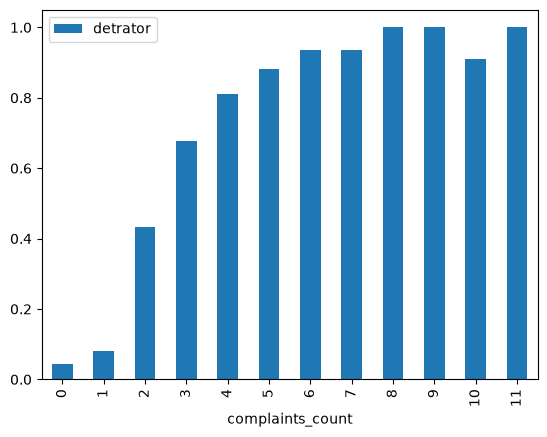

In [44]:
df[['customer_service_contacts', 'detrator']].groupby('customer_service_contacts').mean().plot(kind='bar')
df[['resolution_time_days', 'detrator']].groupby('resolution_time_days').mean().plot(kind='bar')

print(df[['complaints_count', 'detrator']].groupby('complaints_count').mean())
df[['complaints_count', 'detrator']].groupby('complaints_count').mean().plot(kind='bar')

In [45]:
df[['complaints_count', 'customer_service_contacts', 'resolution_time_days']].corr(method='spearman')

,complaints_count,customer_service_contacts,resolution_time_days
complaints_count,1.000000,0.735918,0.024351
customer_service_contacts,0.735918,1.000000,0.015807
resolution_time_days,0.024351,0.015807,1.000000


aqui percebo que dos 3 gráficos, resolution_time_days e customer_service_contacts tem o mesmo problema encontrato em delivery_delay_days, onde mesmo em 0 o percentual de detratores ainda é muito alto. Apenas complaints_count mostra o esperado, que seria quando há 0 reclamações, o número de detratores ser baixo, e ir aumentando conforme o número cresce. Fiz a correlação apenas entre as três variáveis de suporte para entender se as três tinham relação. Aqui chama atenção que resolution_time_days não tem correlação forte. Apesar de não ter correlação forte, assumi que a quantidade de contatos com suporte e reclamações afeta indiretamente o tempo de resposta do suporte.


Com todos esses pontos, entendo que a variável mais relevante para o NPS passa a ser o complaints_count.

Aqui faço uma nova reavaliação de relação entre os datasets para validar o contrário do kruskal anterior, ou seja, quero não rejeitar H0 para ter certeza que essas variáveis não são relevantes para a análise do NPS.

In [46]:
from scipy.stats import kruskal

promotor = df_cs_problem[df_cs_problem['nps_cat'] == 'promotor'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]
neutro = df_cs_problem[df_cs_problem['nps_cat'] == 'neutro'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]
detrator = df_cs_problem[df_cs_problem['nps_cat'] == 'detrator'][['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments']]
kruskal(promotor, neutro, detrator)

KruskalResult(statistic=array([0.49656096, 0.65071009, 2.51599816, 3.94782408, 1.08601256,
       0.72177994]), pvalue=array([0.7801411 , 0.72227087, 0.28422216, 0.13891236, 0.58099898,
       0.69705569]))

In [47]:
tabela_regiao = pd.crosstab(df_cs_problem['customer_region'], df_cs_problem['nps_cat'])

In [48]:
from scipy.stats import chi2_contingency
chi2_contingency(tabela_regiao)

Chi2ContingencyResult(statistic=np.float64(2.9121806203417573), pvalue=np.float64(0.9397471198029157), dof=8, expected_freq=array([[347.29511506,  98.74444893,  18.96043601],
       [358.49818329, 101.92975373,  19.57206298],
       [374.92935002, 106.60153411,  20.46911587],
       [386.87928946, 109.99919257,  21.12151797],
       [382.39806217, 108.72507065,  20.87686718]]))

In [49]:
df_bins = df_cs_problem[['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'nps_cat'  ]].copy()

In [50]:
df_bins['customer_age_bin'] = pd.cut(df_bins['customer_age'], bins=[0, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels=['0-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90', '91-100'])

In [51]:
df_bins['tenure_bin'] = pd.cut(df_bins['customer_tenure_months'], bins=[0, 12, 24, 36, 48, 60, 72, 84, 96, 108, 120], labels=['0-12', '13-24', '25-36', '37-48', '49-60', '61-72', '73-84', '85-96', '97-108', '109-120'])
df_bins['order_value_bin'] = pd.qcut(df_bins['order_value'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])


In [52]:
promotor_bin = df_bins[df_bins['nps_cat'] == 'promotor'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]
neutro_bin = df_bins[df_bins['nps_cat'] == 'neutro'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]
detrator_bin = df_bins[df_bins['nps_cat'] == 'detrator'][['customer_age_bin', 'tenure_bin', 'order_value_bin']]

In [53]:
df_bins['detrator'] = df_bins['nps_cat'] == 'detrator'

In [54]:
df_bins.groupby('customer_age_bin')['detrator'].mean()

customer_age_bin
0-20     0.794702
21-30    0.723596
31-40    0.776000
41-50    0.742798
51-60    0.748963
61-70    0.721550
Name: detrator, dtype: float64

In [55]:
df_bins.groupby('tenure_bin')['detrator'].mean()

tenure_bin
0-12       0.773109
13-24      0.719512
25-36      0.738589
37-48      0.743478
49-60      0.745968
61-72      0.692623
73-84      0.745704
85-96      0.773279
97-108     0.774059
109-120    0.762846
Name: detrator, dtype: float64

In [56]:
df_bins.groupby('order_value_bin')['detrator'].mean()

order_value_bin
Q1    0.766129
Q2    0.736672
Q3    0.756058
Q4    0.728595
Name: detrator, dtype: float64

In [66]:
cross_age_bin = pd.crosstab(df_bins['customer_age_bin'], df_bins['nps_cat'])

chi2_contingency(cross_age_bin)

Chi2ContingencyResult(statistic=np.float64(13.711347713923525), pvalue=np.float64(0.18656970587137697), dof=10, expected_freq=array([[112.77755349,  32.0654017 ,   6.15704481],
       [332.35769075,  94.49737586,  18.14493339],
       [373.43560759, 106.17682681,  20.3875656 ],
       [362.97941058, 103.20387566,  19.81671377],
       [359.99192572, 102.35446104,  19.65361324],
       [308.45781187,  87.70205894,  16.84012919]]))

In [67]:
cross_age_bin = pd.crosstab(df_bins['order_value_bin'], df_bins['nps_cat'])

chi2_contingency(cross_age_bin)

Chi2ContingencyResult(statistic=np.float64(5.124159847963158), pvalue=np.float64(0.527990299354522), dof=6, expected_freq=array([[463.06015341, 131.65926524,  25.28058135],
       [462.3132822 , 131.44691159,  25.23980622],
       [462.3132822 , 131.44691159,  25.23980622],
       [462.3132822 , 131.44691159,  25.23980622]]))

Esse notebook foi escrito após a avaliação, para organização de ideias e documentação. O EDA real foi realizado em eda.ipynb e investigacoes_suporte.ipynb.